# Prevalence of non-isochrony

Bertolo et al. (2026) regard dyads as near-isochronous when their rhythm ratio `r = x / (x + y)` falls in the isochrony window `[0.444, 0.555]`. We reformulate this as a relative criterion: a dyad is isochronous when its non-isochrony `|r - 0.5|` is below a threshold `rho`, where the conventional choice is `rho = 0.05`. We complement it with an absolute criterion, `|x - y| < tau`, with `tau` in milliseconds. Instead of picking a single threshold, we sweep both thresholds to see how sensitive the predominance of (non-)isochrony is to that choice.

Every dyad is classified from its own durations, so nothing here depends on labels or dyad clusters. Percentages are computed within each bird and then averaged across birds.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

import sys
sys.path.append('../src')

from viz.utils import savefig, set_mpl_style, subplot_title
set_mpl_style()
from pipeline.collect_metrics import load_dyad_scores
from metrics.dyad import threshold50


In [2]:
dyads = load_dyad_scores()

In [3]:
# One grid per criterion, fine enough to read the 50% crossing straight off
# the sweep; the drawn curve is subsampled at plot time (see `_thin`).
ABS_THRESHOLDS = np.linspace(0, 100, 200)   # ms, 0.5ms steps
REL_THRESHOLDS = np.linspace(0, 0.4, 200)  # rho, 0.002 steps

LITERATURE_RHO = 0.05

In [4]:
ROW_GROUPS = [
    # (title, datasets, rhythm_type, color_key, style_key)
    ('RT & BWPS',              ['rt', 'bwps-clean'], 'syll_ioi', 'syll', 'rt_bwps'),
    ('NS & BVS (syll. IOIs)',  ['ns', 'bvs'],         'syll_ioi', 'syll', 'ioi'),
    ('NS & BVS (syll. dur.)',  ['ns', 'bvs'],         'syll_dur', 'syll', 'dur'),
    ('NS & BVS (gaps)',        ['ns', 'bvs'],         'gap_dur',  'gap',  'dur'),
    ('BVS only (elem. IOIs)',  ['bvs'],               'elem_ioi', 'elem', 'ioi'),
    ('BVS only (elem. dur.)',  ['bvs'],               'elem_dur', 'elem', 'dur'),
]

COLORS = {'syll': 'C0', 'elem': 'C1', 'gap': 'C2'}
LINESTYLES = {'ioi': '-', 'dur': '--', 'rt_bwps': '-'}
MARKERS = {'ioi': None, 'dur': None, 'rt_bwps': 'x'}
COLOR_LABELS = {'syll': 'Syllables', 'elem': 'Elements', 'gap': 'Gaps'}
STYLE_LABELS = {'ioi': 'IOIs', 'dur': 'Durations', 'rt_bwps': 'RT & BWPS (IOIs)'}

In [5]:
def pooled_subset(dyads, datasets, rhythm_type):
    """Dyads of the given datasets' condition, pooled across their birds."""
    return dyads.query('dataset_id in @datasets and rhythm_type == @rhythm_type')


def bird_shares(subset, criterion_col, thresholds):
    """Per bird (rows) and threshold (columns), the share of dyads that are isochronous,
    i.e. whose criterion value is below the threshold."""
    thresholds = np.asarray(thresholds)
    shares = {
        bird_id: np.searchsorted(np.sort(values.to_numpy()), thresholds, side='left') / len(values)
        for bird_id, values in subset[criterion_col].groupby(level='bird_id')
    }
    return pd.DataFrame(shares, index=thresholds).T


def pooled_sweep(dyads, row_groups, thresholds, criterion_col):
    """% non-isochronous dyads (mean across birds of the per-bird percentage), one row per row group."""
    rows = {}
    for title, datasets, rhythm_type, color_key, style_key in row_groups:
        subset = pooled_subset(dyads, datasets, rhythm_type)
        rows[title] = 1 - bird_shares(subset, criterion_col, thresholds).mean()
    return pd.DataFrame(rows).T


curves_rel = pooled_sweep(dyads, ROW_GROUPS, REL_THRESHOLDS, 'non_isochrony')
curves_abs = pooled_sweep(dyads, ROW_GROUPS, ABS_THRESHOLDS, 'asymmetry')

### Relative vs. absolute criterion

In [6]:
def row_thresholds(row_groups):
    """rho50 and tau50 (ms) of each row: the threshold at which half of the dyads are isochronous."""
    rows = {}
    for title, datasets, rhythm_type, color_key, style_key in row_groups:
        subset = pooled_subset(dyads, datasets, rhythm_type)
        rows[title] = {
            'rho_50': threshold50(subset['non_isochrony']),
            'T_50': threshold50(subset['asymmetry']),
        }
    return pd.DataFrame(rows).T

crossings = row_thresholds(ROW_GROUPS)
crossings

,rho_50,T_50
RT & BWPS,0.093481,51.880
NS & BVS (syll. IOIs),0.098727,52.200
NS & BVS (syll. dur.),0.117080,47.883
NS & BVS (gaps),0.083328,11.827
BVS only (elem. IOIs),0.180354,38.614
BVS only (elem. dur.),0.135596,23.907


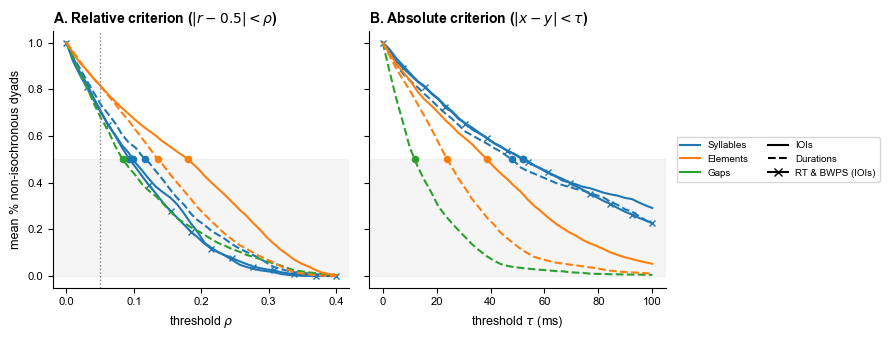

In [7]:
def _thin(curve, n_points=40, n_markers=12):
    """Subsample a sweep curve for drawing."""
    idx = np.unique(np.linspace(0, len(curve) - 1, n_points).round().astype(int))
    xs = np.asarray(curve.index, dtype=float)[idx]
    ys = curve.to_numpy()[idx]
    return xs, ys, max(1, len(xs) // n_markers)


def plot_pooled(rel_df, abs_df, ylabel, crossings=None, ref_rho=LITERATURE_RHO, n_points=40):
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)

    for ax in (ax0, ax1):
        ax.axhspan(0, 0.5, color='.5', alpha=0.08, zorder=0)

    for title, datasets, rhythm_type, color_key, style_key in ROW_GROUPS:
        color = COLORS[color_key]
        kws = dict(color=color, ls=LINESTYLES[style_key], marker=MARKERS[style_key], ms=4, zorder=2)
        for ax, df in ((ax0, rel_df), (ax1, abs_df)):
            xs, ys, markevery = _thin(df.loc[title], n_points=n_points)
            ax.plot(xs, ys, markevery=markevery, **kws)
        if crossings is not None:
            ax0.scatter(crossings.loc[title, 'rho_50'], 0.5, color=color, zorder=3, s=20)
            ax1.scatter(crossings.loc[title, 'T_50'], 0.5, color=color, zorder=3, s=20)

    subplot_title(0, 'Relative criterion ($|r-0.5| < \\rho$)', ax=ax0)
    ax0.set_xlabel('threshold $\\rho$')
    ax0.set_ylabel(ylabel)
    ax0.axvline(ref_rho, c='gray', ls=':', lw=1)
    ax0.set_ylim(-0.05, 1.05)

    subplot_title(1, 'Absolute criterion ($|x-y| < \\tau$) ', ax=ax1)
    ax1.set_xlabel('threshold $\\tau$ (ms)')

    sns.despine()
    from matplotlib.lines import Line2D
    color_handles = [Line2D([], [], color=c, label=COLOR_LABELS[k]) for k, c in COLORS.items()]
    style_handles = [Line2D([], [], color='k', ls=LINESTYLES[k], marker=MARKERS[k], label=STYLE_LABELS[k])
                     for k in LINESTYLES]
    ax1.legend(handles=color_handles + style_handles, fontsize=7, ncols=2,
               loc='center left', bbox_to_anchor=(1.02, 0.5))
    fig.tight_layout()
    return fig, (ax0, ax1)


plot_pooled(curves_rel, curves_abs, 'mean % non-isochronous dyads', crossings=crossings)
crossings
savefig('figS6-predominance')

### Per-bird trajectories

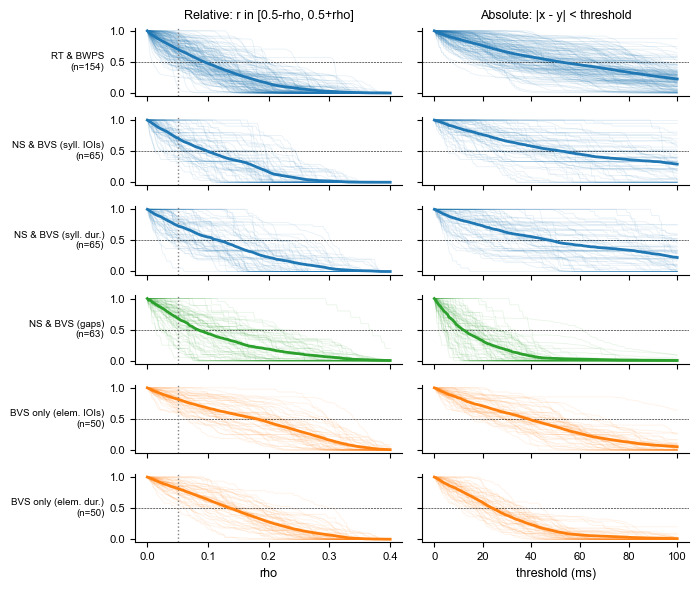

In [8]:
fig, axes = plt.subplots(len(ROW_GROUPS), 2, figsize=(7, 1 * len(ROW_GROUPS)), sharex='col', sharey=True)

for row, (title, datasets, rhythm_type, color_key, style_key) in enumerate(ROW_GROUPS):
    color = COLORS[color_key]
    ax0, ax1 = axes[row]

    subset = pooled_subset(dyads, datasets, rhythm_type)
    rel_matrix = 1 - bird_shares(subset, 'non_isochrony', REL_THRESHOLDS)
    abs_matrix = 1 - bird_shares(subset, 'asymmetry', ABS_THRESHOLDS)

    for _, traj in rel_matrix.iterrows():
        ax0.plot(REL_THRESHOLDS, traj, color=color, alpha=0.1, lw=0.6, zorder=1)
    for _, traj in abs_matrix.iterrows():
        ax1.plot(ABS_THRESHOLDS, traj, color=color, alpha=0.1, lw=0.6, zorder=1)

    ax0.plot(REL_THRESHOLDS, curves_rel.loc[title], color=color, lw=2, zorder=3)
    ax1.plot(ABS_THRESHOLDS, curves_abs.loc[title], color=color, lw=2, zorder=3)

    for ax in (ax0, ax1):
        ax.axhline(.5, c='k', ls='--', lw=.4, zorder=2)
    ax0.axvline(LITERATURE_RHO, c='gray', ls=':', lw=1, zorder=2)
    ax0.set_ylabel(f'{title}\n(n={len(rel_matrix)})', rotation=0, ha='right', va='center', fontsize=7)

axes[0, 0].set_title('Relative: r in [0.5-rho, 0.5+rho]', fontsize=9)
axes[0, 1].set_title('Absolute: |x - y| < threshold', fontsize=9)
axes[-1, 0].set_xlabel('rho')
axes[-1, 1].set_xlabel('threshold (ms)')
axes[0, 0].set_ylim(-0.05, 1.05)

sns.despine()
fig.tight_layout()